<a href="https://colab.research.google.com/github/tovarrog24/Emergency-Department-Volume-and-Capacity/blob/main/code/learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Emergency Department Forecasting and Optimization

**Class:** CS-4330-D10, Introduction to Data Science, Fall 2026 (Angelo State University, Dr. Dogdu)

**Team (Group 2):**

- Rogelio "Anthony" Tovar, rtovar3@angelo.edu, major: Mathematics
- Virgil Rogers, vrogers4@angelo.edu, major: Artificial Intelligence

**Project description:** Emergency departments (EDs) are where demand for hospital care is least predictable. When an ED sees more patients than its treatment stations can handle, wait times grow and care suffers. Our project uses California's hospital-level ED data to find which hospitals carry the heaviest ED load, how that load relates to hospital size and type, and which kinds of hospitals look alike, so that planners can see where added capacity is most needed.

**Dataset:**

- Source: *Emergency Department Volume and Capacity, 2021–2023*, California Department of Health Care Access and Information (HCAI), via Data.gov: https://catalog.data.gov/dataset/emergency-department-volume-and-capacity
- Original size: 12,849 rows and 18 features (one row per hospital, year, and diagnosis category).
- File used here: `ED_Cleaned.csv`, the hospital-level table from Progress Report #1, with 756 rows (one per hospital per year, 297 hospitals) and 19 features.
- Schema: identifiers (`oshpd_id`, `FacilityName2`, `CountyName`, `system`); numerical features (`year`, `Tot_ED_NmbVsts`, `EDStations`, `ED_Burden`, `Bed_Size_Rank`, `LATITUDE`, `LONGITUDE`, `LAT_STD`, `LON_STD`); categorical features (`LICENSED_BED_SIZE`, `HospitalOwnership`, `UrbanRuralDesi`, `TEACHINGDesignation`, `PrimaryCareShortageArea`, `MentalHealthShortageArea`). `ED_Burden` is total ED visits divided by ED treatment stations.

**Project goals:**

1. Predict how heavily a hospital's ED is used from its size and type (regression, Reports #2 and #3).
2. Classify hospitals by setting, health system, and shortage-area status (classification, Report #3 and this report).
3. Group hospitals and health systems with similar demand profiles (clustering, this report).

**Report title:** Progress Report #4: Supervised and Unsupervised Learning

Sections 1.1, 2.1, and 2.2: Rogelio Tovar. Section 1.2 (Support Vector Machine), the write-up, and the conclusion: Virgil Rogers.

## 0. Setup

We import the libraries used throughout the notebook and load the cleaned dataset. When the repository is cloned, the notebook reads `../dataset/ED_Cleaned.csv`. When it is opened in Colab straight from GitHub, that folder is not available, so it loads the same file from our repository.

In [1]:
# Progress Report #4: Supervised and Unsupervised Learning | Group 2 (Tovar and Rogers) | CS-4330-D10, Fall 2026

# Import packages
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist
from mlxtend.plotting import plot_decision_regions

from pathlib import Path
import warnings
warnings.simplefilter("ignore")

LOCAL_PATH = Path("../dataset/ED_Cleaned.csv")
REPO_URL = ("https://raw.githubusercontent.com/tovarrog24/"
            "Emergency-Department-Volume-and-Capacity/main/dataset/ED_Cleaned.csv")
source = LOCAL_PATH if LOCAL_PATH.exists() else REPO_URL

data = pd.read_csv(source)
print("Loaded from:", source)
print("Shape:", data.shape)

Loaded from: ../dataset/ED_Cleaned.csv
Shape: (756, 19)


The file loads with 756 rows and 19 columns. Each row is one California hospital in one year.

Several of the models below try to predict which health system a hospital belongs to, so we first list the systems in the data and how many hospital-years each one has.

In [2]:
print("Number of systems:", data["system"].nunique())
print(data["system"].value_counts().head(8).to_string())

Number of systems: 32
system
No System                       212
Kaiser Foundation Hospitals      93
Dignity Health                   70
Sutter Health                    59
Adventist Health Systems         43
Providence St. Joseph Health     43
Prime Healthcare Services        38
Tenet Healthcare Corporation     31


There are 32 system labels. The largest by far is "No System" (212 hospital-years), which marks independent hospitals, followed by Kaiser Foundation Hospitals (93) and Dignity Health (70). Most of the other systems have only a handful of hospitals, which makes system a hard target: a model has very few examples to learn from for most classes.

## 1. Supervised Learning

Task: try one or more supervised learning algorithms from K-nearest Neighbors, Naive Bayes, and Support Vector Machine, apply them to the dataset, and show how effective they are.

We use two algorithms. Section 1.1 applies K-nearest Neighbors (KNN) and Section 1.2 applies a Support Vector Machine (SVM).

## 1.1 K-nearest Neighbors

KNN classifies a hospital by looking at the k hospitals closest to it in the feature space and taking a majority vote of their labels. We use k = 5 throughout. Because KNN works on distances, the features are standardized first so that a feature measured in large numbers (such as visits) does not drown out one measured in small numbers (such as bed size rank).

### 1.1.1 Health system from ED burden and bed size rank

Our first attempt asks whether a hospital's health system can be predicted from two numerical features, `ED_Burden` and `Bed_Size_Rank`. We hold out 30% of the rows for testing and report the accuracy next to the no-skill rate (the accuracy of always guessing the most common system). The plot shows the regions of the feature space that KNN assigns to each system, using a sample of 200 rows to keep the run time low.

Predicted system for a hospital with ED_Burden = 1400 and Bed_Size_Rank = 5: Kaiser Foundation Hospitals
Accuracy: 0.28634361233480177
No-skill accuracy (always guess the most common system): 0.27312775330396477


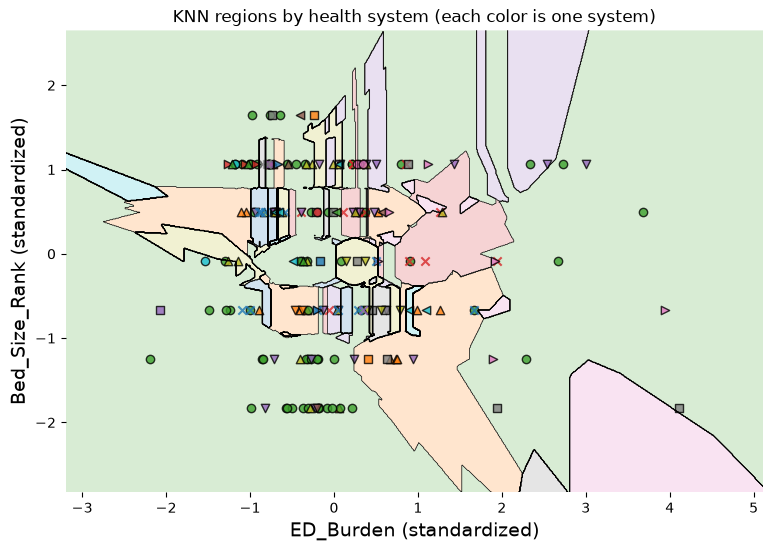

In [3]:
#Trying to use K-nearest Neighbors to classify certain data

#We will try to classify the system a hospital is in from the following two numerical features: ED_Burden; Bed_Size_Rank
systemClassifier = KNeighborsClassifier(n_neighbors = 5)

# Split data
X = data[["ED_Burden", "Bed_Size_Rank"]]
y = data[["system"]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Scale data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Train model and make predictions for the test set.
systemClassifier.fit(X_train_scaled, np.ravel(y_train))
y_pred = systemClassifier.predict(scaler.transform(X_test))

# Predict one hospital
hos = pd.DataFrame(data={"ED_Burden": [1400], "Bed_Size_Rank": [5]})
print("Predicted system for a hospital with ED_Burden = 1400 and Bed_Size_Rank = 5:",
      systemClassifier.predict(scaler.transform(hos))[0])

# Compute metrics
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))
print("No-skill accuracy (always guess the most common system):",
      y_test["system"].value_counts(normalize=True).max())

# Take a sample to keep runtime low while seeing what areas are classified as each hospital
systemSample = data.sample(200, random_state=123).copy()

# Create integer-valued labels for plot_decision_regions()
systemCodes = {name: code for code, name in enumerate(data["system"].unique())}
systemSample["Int"] = systemSample["system"].map(systemCodes)

# Define input and output features
X = systemSample[["ED_Burden", "Bed_Size_Rank"]]
y = systemSample[["Int"]]

# Scale the sample and fit model
X_plot = StandardScaler().fit_transform(X)
systemClassifier.fit(X_plot, np.ravel(y))

# Set background opacity to 20%
contourf_kwargs = {"alpha": 0.2}

# Plot decision boundary regions
plt.figure(figsize=(9, 6))
p = plot_decision_regions(
    X_plot, np.ravel(y), clf=systemClassifier, contourf_kwargs=contourf_kwargs, legend=0
)

# Add title and axis labels
p.set_xlabel("ED_Burden (standardized)", fontsize=14)
p.set_ylabel("Bed_Size_Rank (standardized)", fontsize=14)
p.set_title("KNN regions by health system (each color is one system)")
plt.show()

KNN classifies 28.6% of the test hospitals into the correct system. That is barely above the 27.3% we would get by always guessing the most common label, "No System." The plot shows why. The colored regions are small and broken up, and hospitals from many different systems sit side by side. Burden and bed size do not differ enough from one system to the next for nearest neighbors to tell them apart.

### 1.1.2 Health system from total ED visits and ED stations

Next we keep the same target and swap in the two direct size measures, `Tot_ED_NmbVsts` and `EDStations`, to see whether they separate the systems any better.

Predicted system for a hospital with Tot_ED_NmbVsts = 40000 and EDStations = 25: Dignity Health
Accuracy: 0.29955947136563876
No-skill accuracy (always guess the most common system): 0.27312775330396477


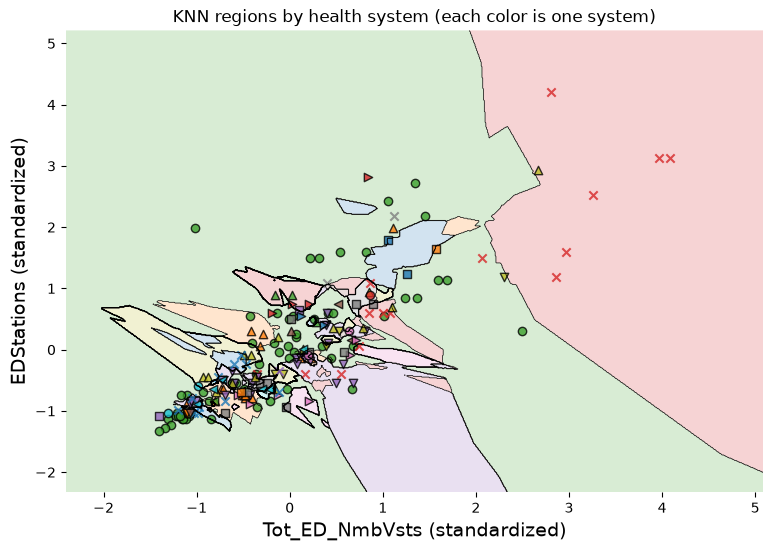

In [4]:
#Trying to use K-nearest Neighbors to classify certain data

#We will try to classify the system a hospital is in from the following two numerical features: Tot_ED_NmbVsts; EDStations
systemClassifier = KNeighborsClassifier(n_neighbors = 5)

# Split data
X = data[["Tot_ED_NmbVsts", "EDStations"]]
y = data[["system"]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Scale data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Train model and make predictions for the test set.
systemClassifier.fit(X_train_scaled, np.ravel(y_train))
y_pred = systemClassifier.predict(scaler.transform(X_test))

# Predict one hospital
hos = pd.DataFrame(data={"Tot_ED_NmbVsts": [40000], "EDStations": [25]})
print("Predicted system for a hospital with Tot_ED_NmbVsts = 40000 and EDStations = 25:",
      systemClassifier.predict(scaler.transform(hos))[0])

# Compute metrics
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))
print("No-skill accuracy (always guess the most common system):",
      y_test["system"].value_counts(normalize=True).max())

# Take a sample to keep runtime low while seeing what areas are classified as each hospital
systemSample = data.sample(200, random_state=123).copy()

# Create integer-valued labels for plot_decision_regions()
systemCodes = {name: code for code, name in enumerate(data["system"].unique())}
systemSample["Int"] = systemSample["system"].map(systemCodes)

# Define input and output features
X = systemSample[["Tot_ED_NmbVsts", "EDStations"]]
y = systemSample[["Int"]]

# Scale the sample and fit model
X_plot = StandardScaler().fit_transform(X)
systemClassifier.fit(X_plot, np.ravel(y))

# Set background opacity to 20%
contourf_kwargs = {"alpha": 0.2}

# Plot decision boundary regions
plt.figure(figsize=(9, 6))
p = plot_decision_regions(
    X_plot, np.ravel(y), clf=systemClassifier, contourf_kwargs=contourf_kwargs, legend=0
)

# Add title and axis labels
p.set_xlabel("Tot_ED_NmbVsts (standardized)", fontsize=14)
p.set_ylabel("EDStations (standardized)", fontsize=14)
p.set_title("KNN regions by health system (each color is one system)")
plt.show()

Using visits and stations raises the accuracy slightly, to 30.0%, still close to the 27.3% no-skill rate. The regions remain fragmented wherever the hospitals are crowded together. The one visible pattern is at the far right of the plot, where the very largest EDs fall into a single region, but that covers only a few hospitals. With 32 classes and two size features, KNN is not effective for predicting the health system.

### 1.1.3 Mental health shortage area from total ED visits and ED stations

With 32 systems, the previous target may simply have too many classes. Here we try a two-class target with the same features: whether the hospital is in a mental health shortage area (1 = yes, 0 = no).

Accuracy: 0.6696035242290749
No-skill accuracy (always guess the most common class): 0.6167400881057269
Confusion matrix (rows = actual No, Yes; columns = predicted No, Yes):
[[111  29]
 [ 46  41]]


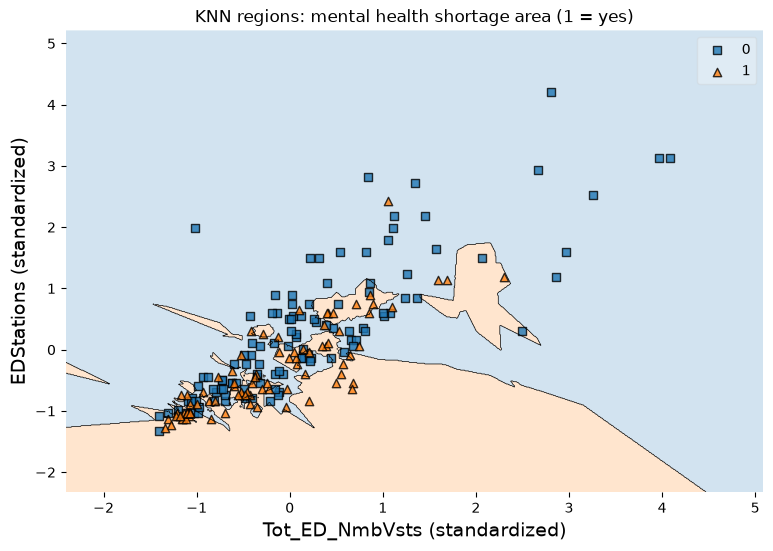

In [5]:
#Trying to use K-nearest Neighbors to classify certain data

#We will try to classify whether a hospital is in a mental health shortage area from: Tot_ED_NmbVsts; EDStations
systemClassifier = KNeighborsClassifier(n_neighbors = 5)

# Split data
X = data[["Tot_ED_NmbVsts", "EDStations"]]
y = data[["MentalHealthShortageArea"]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Scale data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Train model and make predictions for the test set.
systemClassifier.fit(X_train_scaled, np.ravel(y_train))
y_pred = systemClassifier.predict(scaler.transform(X_test))

# Compute metrics
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))
print("No-skill accuracy (always guess the most common class):",
      y_test["MentalHealthShortageArea"].value_counts(normalize=True).max())
print("Confusion matrix (rows = actual No, Yes; columns = predicted No, Yes):")
print(metrics.confusion_matrix(y_test, y_pred, labels=["No", "Yes"]))

# Take a sample to keep runtime low
systemSample = data.sample(200, random_state=123).copy()

# Create integer-valued labels for plot_decision_regions()
systemSample["Int"] = systemSample["MentalHealthShortageArea"].map({"No": 0, "Yes": 1})

# Define input and output features
X = systemSample[["Tot_ED_NmbVsts", "EDStations"]]
y = systemSample[["Int"]]

# Scale the sample and fit model
X_plot = StandardScaler().fit_transform(X)
systemClassifier.fit(X_plot, np.ravel(y))

# Set background opacity to 20%
contourf_kwargs = {"alpha": 0.2}

# Plot decision boundary regions
plt.figure(figsize=(9, 6))
p = plot_decision_regions(
    X_plot, np.ravel(y), clf=systemClassifier, contourf_kwargs=contourf_kwargs
)

# Add title and axis labels
p.set_xlabel("Tot_ED_NmbVsts (standardized)", fontsize=14)
p.set_ylabel("EDStations (standardized)", fontsize=14)
p.set_title("KNN regions: mental health shortage area (1 = yes)")
plt.show()

With only two classes the model does somewhat better. It is correct for 67.0% of the test hospitals, compared with 61.7% for always guessing "No." The confusion matrix shows the weakness: of the 87 hospitals that really are in a shortage area, KNN identifies 41, which is under half. In the plot, the largest EDs at the top fall mostly in the non-shortage region, but in the crowded lower left, where most hospitals sit, the two classes are mixed together and the boundary breaks into small patches. Visits and stations carry a little information about shortage areas, but not much.

### 1.1.4 Splitting the data into urban and non-urban hospitals

The features we tried do not form clear groups across the full dataset. One possible reason is that urban and non-urban hospitals behave differently, so mixing them blurs the picture. Here we partition the data into urban hospitals and non-urban (rural and frontier) hospitals, and check how common mental health shortage areas are in each group.

In [6]:
urbanData = data[data["UrbanRuralDesi"] == "Urban"].copy()

nonUrbanData = data[data["UrbanRuralDesi"] != "Urban"].copy()

print("Urban hospital-years:", len(urbanData), "| Non-urban hospital-years:", len(nonUrbanData))
print("\nShare of each group in a mental health shortage area:")
print(pd.crosstab(data["UrbanRuralDesi"] == "Urban", data["MentalHealthShortageArea"], normalize="index")
      .rename(index={True: "Urban", False: "Non-urban"}).round(3))

Urban hospital-years: 589 | Non-urban hospital-years: 167

Share of each group in a mental health shortage area:
MentalHealthShortageArea     No    Yes
UrbanRuralDesi                        
Non-urban                 0.162  0.838
Urban                     0.722  0.278


The split leaves 589 urban and 167 non-urban hospital-years, and the two groups turn out to be very different. About 84% of the non-urban hospitals are in a mental health shortage area, compared with about 28% of the urban hospitals. We had expected shortage areas to be common in cities as well, so this was a surprise. It also tells us that knowing whether a hospital is urban already says a lot about its shortage status.

We now draw the KNN decision regions separately for each group, again predicting mental health shortage area (1 = yes) from total ED visits and ED stations. Each plot uses a sample of up to 200 rows, with standardized features.

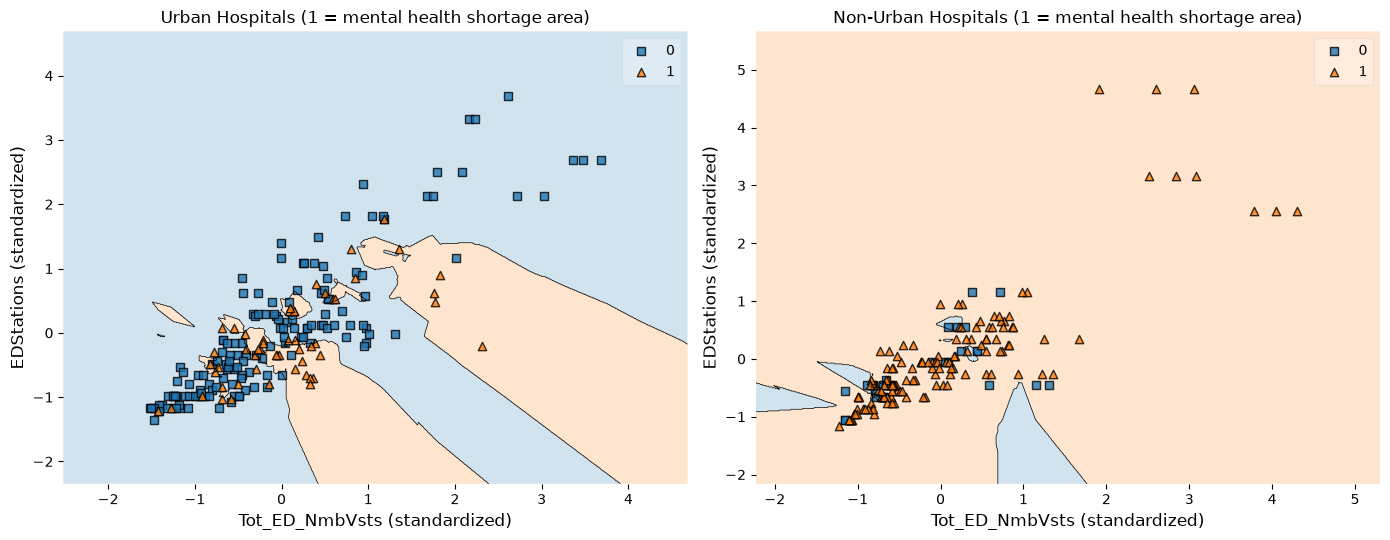

In [7]:
def plotKNN(dataset, title, ax):

    # Take a sample
    systemSample = dataset.sample(
        min(200, len(dataset)),
        random_state=123
    ).copy()

    # Convert labels to integers
    systemSample["Int"] = systemSample["MentalHealthShortageArea"].map(
        {"No": 0, "Yes": 1}
    )

    # Define features and target
    X = systemSample[["Tot_ED_NmbVsts", "EDStations"]]
    y = systemSample["Int"]

    # Scale features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Fit model
    systemClassifier = KNeighborsClassifier(n_neighbors=5)
    systemClassifier.fit(X_scaled, y)

    # Plot decision regions
    contourf_kwargs = {"alpha": 0.2}

    p = plot_decision_regions(
        X_scaled,
        y.to_numpy(),
        clf=systemClassifier,
        contourf_kwargs=contourf_kwargs,
        ax=ax
    )

    p.set_xlabel("Tot_ED_NmbVsts (standardized)", fontsize=12)
    p.set_ylabel("EDStations (standardized)", fontsize=12)
    p.set_title(title)

    return p

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plotKNN(urbanData, "Urban Hospitals (1 = mental health shortage area)", axes[0])
plotKNN(nonUrbanData, "Non-Urban Hospitals (1 = mental health shortage area)", axes[1])
plt.tight_layout()
plt.show()

Among urban hospitals, most of the plot belongs to class 0 (not a shortage area), with pockets of class 1 scattered among the small and mid-sized EDs. Among non-urban hospitals the picture is reversed: nearly the whole plot belongs to class 1. The few non-shortage hospitals in the non-urban group sit among the shortage hospitals instead of in a region of their own.

To measure how effective KNN is within each group, we split each sample into training (80%) and testing (20%) sets, keeping the class proportions the same in both, and report the accuracy, the confusion matrix, and the classification report.

In [8]:
def evaluateKNN(dataset, title):

    # Take a sample
    systemSample = dataset.sample(
        min(200, len(dataset)),
        random_state=123
    ).copy()

    # Convert labels to integers
    systemSample["Int"] = systemSample["MentalHealthShortageArea"].map(
        {"No": 0, "Yes": 1}
    )

    # Define features and target
    X = systemSample[["Tot_ED_NmbVsts", "EDStations"]]
    y = systemSample["Int"]

    # Divide into training and testing data
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # Scale features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Fit model
    systemClassifier = KNeighborsClassifier(n_neighbors=5)
    systemClassifier.fit(X_train_scaled, y_train)

    # Make predictions
    predictions = systemClassifier.predict(X_test_scaled)

    # Evaluate model
    print("\n", title)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("No-skill accuracy:", max(y_test.mean(), 1 - y_test.mean()))
    print("\nConfusion Matrix (rows = actual 0, 1; columns = predicted 0, 1):")
    print(confusion_matrix(y_test, predictions))
    print("\nClassification Report:")
    print(classification_report(y_test, predictions, zero_division=0))

# Evaluate effectiveness
evaluateKNN(urbanData, "Urban Hospitals")
evaluateKNN(nonUrbanData, "Non-Urban Hospitals")


 Urban Hospitals
Accuracy: 0.725
No-skill accuracy: 0.725

Confusion Matrix (rows = actual 0, 1; columns = predicted 0, 1):
[[25  4]
 [ 7  4]]

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.86      0.82        29
           1       0.50      0.36      0.42        11

    accuracy                           0.72        40
   macro avg       0.64      0.61      0.62        40
weighted avg       0.70      0.72      0.71        40


 Non-Urban Hospitals
Accuracy: 0.8529411764705882
No-skill accuracy: 0.8529411764705882

Confusion Matrix (rows = actual 0, 1; columns = predicted 0, 1):
[[ 0  5]
 [ 0 29]]

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         5
           1       0.85      1.00      0.92        29

    accuracy                           0.85        34
   macro avg       0.43      0.50      0.46        34
weighted avg       0.73      0.85  

At first glance the accuracies look good, at 72.5% for urban hospitals and 85.3% for non-urban hospitals. In both groups, however, the accuracy is exactly the same as the no-skill rate. For the urban group, KNN finds only 4 of the 11 shortage-area hospitals in the test set. For the non-urban group, it predicts "shortage area" for every hospital and so misses all 5 that are not. Splitting the data taught us something useful about the hospitals, namely that urban and non-urban hospitals differ sharply in shortage status, but within each group, visits and stations do not help KNN beyond guessing the majority class. The test sets here are also small (40 and 34 hospitals), so these figures are rough. Section 1.2 tries a different algorithm with more informative features.

## 1.2 Support Vector Machine

A Support Vector Machine separates two classes by finding the boundary that leaves the widest possible margin between them. With a kernel, the boundary can curve: the radial basis function (RBF) kernel lets the model draw rounded regions instead of a single straight line. Two settings control the fit. `C` sets how heavily the model is penalized for misclassified training points (a larger C means a tighter fit), and `gamma` sets how far the influence of a single point reaches (a larger gamma means a more local, wigglier boundary).

Section 1.1 showed that two size features alone do not separate these hospitals well. In this section we give the SVM more to work with and test it carefully.

### 1.2.1 Target, features, and an honest test set

Target: whether a hospital is urban (1) or rural/frontier (0). This is the classification task from Report #3, where logistic regression reached about 90% accuracy, so we have a benchmark to beat.

Features: six numerical attributes, namely ED stations, bed size rank, total ED visits, ED burden, latitude, and longitude.

Most hospitals appear in two or three years with nearly the same values each year. If rows are split at random, the same hospital lands in both the training and test sets, and the model is graded on hospitals it has effectively already seen. To avoid that, we hold out 25% of the hospitals (all of their years) as a test set that is not touched until the final evaluation. We assign hospitals with a fixed random seed so the split is identical on every computer.

In [9]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import PredefinedSplit, GridSearchCV, cross_val_score
from sklearn.metrics import balanced_accuracy_score, ConfusionMatrixDisplay

SVM_FEATURES = ["EDStations", "Bed_Size_Rank", "Tot_ED_NmbVsts", "ED_Burden", "LAT_STD", "LON_STD"]
X_all = data[SVM_FEATURES]
y_urban = (data["UrbanRuralDesi"] == "Urban").astype(int)

# Hold out 25% of hospitals (all of their years) as the final test set
hospitals = np.sort(data["oshpd_id"].unique())
shuffled = np.random.RandomState(42).permutation(hospitals)
test_hospitals = set(shuffled[: len(hospitals) // 4])
is_test = data["oshpd_id"].isin(test_hospitals).to_numpy()

X_train_svm, X_test_svm = X_all[~is_test], X_all[is_test]
y_train_svm, y_test_svm = y_urban[~is_test], y_urban[is_test]

# Five folds within the training hospitals, again keeping each hospital in one fold
train_hospitals = [h for h in shuffled if h not in test_hospitals]
fold_of = {h: i % 5 for i, h in enumerate(train_hospitals)}
cv_train = PredefinedSplit(data.loc[~is_test, "oshpd_id"].map(fold_of).to_numpy())

print(f"Training set: {len(X_train_svm)} rows from {len(train_hospitals)} hospitals")
print(f"Test set:     {len(X_test_svm)} rows from {len(test_hospitals)} hospitals")
print("Hospitals in both sets:", len(set(train_hospitals) & test_hospitals))
print(f"Urban share: training {y_train_svm.mean():.3f}, test {y_test_svm.mean():.3f}")

Training set: 570 rows from 223 hospitals
Test set:     186 rows from 74 hospitals
Hospitals in both sets: 0
Urban share: training 0.775, test 0.790


The training set has 570 rows from 223 hospitals and the test set has 186 rows from 74 hospitals, with no hospital in both. The share of urban hospitals is nearly the same in the two sets (77.5% and 79.0%), so the test set is a fair sample. A model that always guessed "urban" would be right 79.0% of the time on the test set, and that is the number any useful model has to beat.

### 1.2.2 Choosing a kernel

We compare three kernels using 5-fold cross-validation inside the training hospitals only: linear (a straight boundary), polynomial of degree 3, and RBF. Each model is a pipeline that standardizes the features and then fits the SVM, so the scaling is learned from the training folds alone. We report accuracy and balanced accuracy (the average of the accuracy within each class), since about 78% of hospitals are urban and plain accuracy can hide poor results on the smaller class.

In [10]:
kernel_rows = {}
for kernel in ["linear", "poly", "rbf"]:
    model = make_pipeline(StandardScaler(), SVC(kernel=kernel))
    acc = cross_val_score(model, X_train_svm, y_train_svm, cv=cv_train, scoring="accuracy")
    bal = cross_val_score(model, X_train_svm, y_train_svm, cv=cv_train, scoring="balanced_accuracy")
    kernel_rows[kernel] = {"CV accuracy": acc.mean(), "CV balanced accuracy": bal.mean()}
pd.DataFrame(kernel_rows).T.round(3)

,CV accuracy,CV balanced accuracy
linear,0.898,0.827
poly,0.880,0.789
rbf,0.905,0.841


The RBF kernel does best on both measures, with a cross-validated accuracy of 90.5% and a balanced accuracy of 0.841. The linear kernel is close behind (89.8% and 0.827), which tells us the two classes are already fairly well separated by a straight boundary. The polynomial kernel is the weakest of the three (88.0% and 0.789). We continue with the RBF kernel.

### 1.2.3 Tuning C and gamma

With the RBF kernel selected, we search a grid of `C` and `gamma` values using the same training folds. `GridSearchCV` fits every combination, scores each by balanced accuracy, and keeps the best one. The heat map shows the score for every combination.

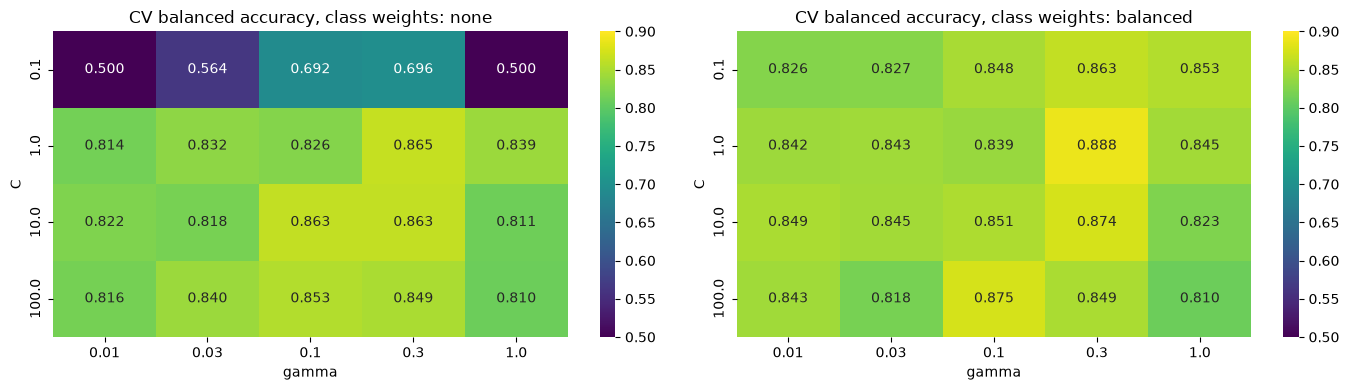

Best settings: {'svc__C': 1, 'svc__class_weight': 'balanced', 'svc__gamma': 0.3}
Best cross-validated balanced accuracy: 0.888


In [11]:
param_grid = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.01, 0.03, 0.1, 0.3, 1],
              "svc__class_weight": [None, "balanced"]}
search = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf")), param_grid,
                      cv=cv_train, scoring="balanced_accuracy")
search.fit(X_train_svm, y_train_svm)

results = pd.DataFrame(search.cv_results_)
results["weights"] = results["param_svc__class_weight"].fillna("none").astype(str).replace("None", "none")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, weights in zip(axes, ["none", "balanced"]):
    grid_scores = (results[results["weights"] == weights]
                   .pivot(index="param_svc__C", columns="param_svc__gamma", values="mean_test_score"))
    sns.heatmap(grid_scores, annot=True, fmt=".3f", cmap="viridis", vmin=0.5, vmax=0.9, ax=ax)
    ax.set(title=f"CV balanced accuracy, class weights: {weights}", xlabel="gamma", ylabel="C")
plt.tight_layout()
plt.show()

print("Best settings:", search.best_params_)
print("Best cross-validated balanced accuracy:", round(search.best_score_, 3))

The best combination is C = 1 and gamma = 0.3 with balanced class weights, at a cross-validated balanced accuracy of 0.888. Two things stand out in the heat maps. First, balancing the class weights helps almost everywhere: the right-hand map is brighter than the left, and the best unweighted score is 0.865. Balanced weights make a mistake on a rural or frontier hospital cost more, which offsets the fact that there are fewer of them. Second, the settings matter. Without class weights, a small C of 0.1 can drop the score to 0.500, which means the model has given up and is predicting "urban" for everyone. A very large gamma also hurts, because the boundary starts to follow individual hospitals.

### 1.2.4 Final test on hospitals the model has never seen

We now evaluate the tuned SVM once on the held-out hospitals. For context, we score three reference points on the same test set: a no-skill rule that always guesses "urban," logistic regression (the Report #3 approach), and KNN with k = 5 (the Section 1.1 algorithm). All use the same six features and the same standardization.

,Test accuracy,Test balanced accuracy,Errors
No-skill (always urban),0.790,0.500,39
Logistic regression,0.903,0.826,18
KNN (k = 5),0.882,0.756,22
"SVM (RBF, default settings)",0.909,0.839,17
"SVM (RBF, tuned)",0.914,0.880,16


Tuned SVM classification report (0 = rural/frontier, 1 = urban):
                precision    recall  f1-score   support

Rural/frontier       0.78      0.82      0.80        39
         Urban       0.95      0.94      0.95       147

      accuracy                           0.91       186
     macro avg       0.87      0.88      0.87       186
  weighted avg       0.92      0.91      0.91       186



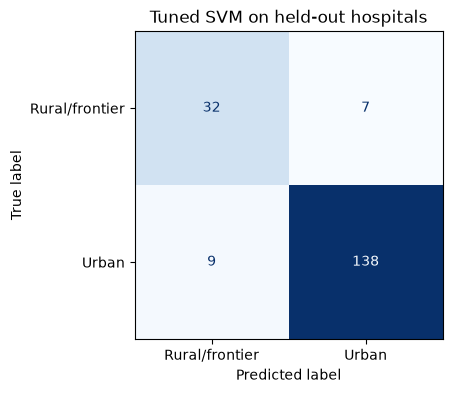

In [12]:
from sklearn.linear_model import LogisticRegression

svm_best = search.best_estimator_
models = {
    "No-skill (always urban)": None,
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN (k = 5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "SVM (RBF, default settings)": make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    "SVM (RBF, tuned)": svm_best,
}
test_rows, test_preds = {}, {}
for name, model in models.items():
    if model is None:
        pred = np.ones(len(y_test_svm), dtype=int)
    else:
        pred = model.fit(X_train_svm, y_train_svm).predict(X_test_svm)
    test_preds[name] = pred
    test_rows[name] = {"Test accuracy": accuracy_score(y_test_svm, pred),
                       "Test balanced accuracy": balanced_accuracy_score(y_test_svm, pred),
                       "Errors": int((pred != y_test_svm).sum())}
test_table = pd.DataFrame(test_rows).T.astype({"Errors": int})
display(test_table.round(3))

svm_pred = test_preds["SVM (RBF, tuned)"]
print("Tuned SVM classification report (0 = rural/frontier, 1 = urban):")
print(classification_report(y_test_svm, svm_pred, target_names=["Rural/frontier", "Urban"]))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test_svm, svm_pred, display_labels=["Rural/frontier", "Urban"],
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Tuned SVM on held-out hospitals")
plt.show()

On the 74 hospitals it had never seen, the tuned SVM classifies 91.4% of hospital-years correctly, with a balanced accuracy of 0.880. It makes 16 errors out of 186, compared with 39 for the no-skill rule. It is also the best of the models we compared:

| Model | Test accuracy | Balanced accuracy | Errors |
|---|---|---|---|
| No-skill (always urban) | 79.0% | 0.500 | 39 |
| KNN (k = 5) | 88.2% | 0.756 | 22 |
| Logistic regression | 90.3% | 0.826 | 18 |
| SVM (RBF, default settings) | 90.9% | 0.839 | 17 |
| SVM (RBF, tuned) | 91.4% | 0.880 | 16 |

The gain in plain accuracy over logistic regression is small, only two fewer errors. The real improvement is in how the errors are distributed. The confusion matrix shows the tuned SVM correctly identifies 32 of the 39 rural and frontier hospital-years (82%) and 138 of the 147 urban ones (94%). The smaller class is the hard one, and tuning with balanced class weights is what lifted the balanced accuracy from 0.839 to 0.880. KNN also does much better here than in Section 1.1 (88.2%), which shows how much the choice of features matters, but it trails the SVM, especially on the rural and frontier hospitals. Because the settings were chosen using the training hospitals only, the test result is an honest estimate, and it lands close to the cross-validated score of 0.888.

### 1.2.5 Seeing the boundary: an SVM map of California

An SVM with six features cannot be drawn directly, so to show how the algorithm works we fit a second, two-feature SVM on latitude and longitude alone. With only location to go on, the SVM has to draw the urban regions of California as curved areas on a map. The plot shows its decision regions with the training hospitals on top. The class weights are balanced so that the smaller rural/frontier class is not ignored.

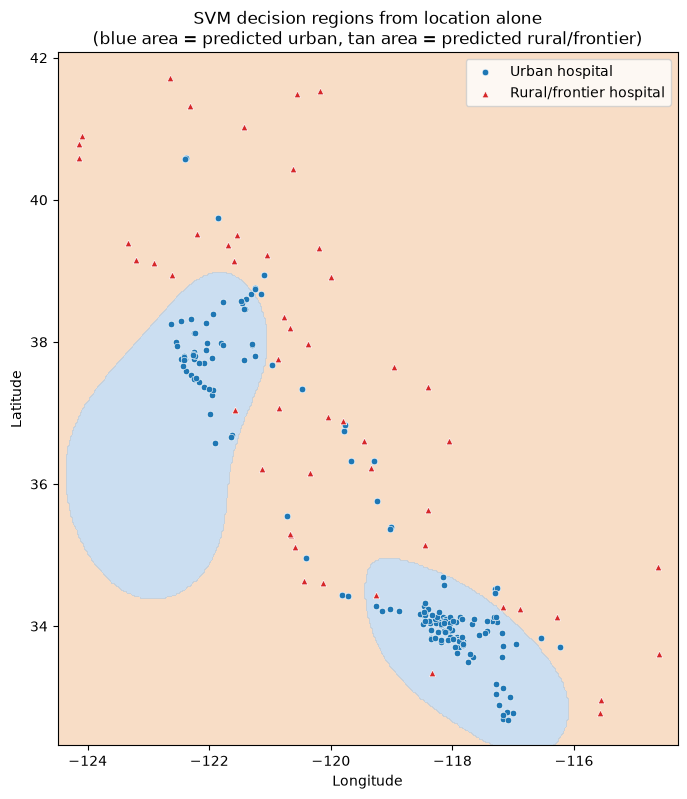

Location-only SVM on held-out hospitals: accuracy 0.887, balanced accuracy 0.891


In [13]:
geo_features = ["LON_STD", "LAT_STD"]
geo_svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma=1, class_weight="balanced"))
geo_svm.fit(X_train_svm[geo_features], y_train_svm)
geo_pred = geo_svm.predict(X_test_svm[geo_features])

lon = np.linspace(data["LON_STD"].min() - 0.3, data["LON_STD"].max() + 0.3, 400)
lat = np.linspace(data["LAT_STD"].min() - 0.3, data["LAT_STD"].max() + 0.3, 400)
lon_grid, lat_grid = np.meshgrid(lon, lat)
grid = pd.DataFrame({"LON_STD": lon_grid.ravel(), "LAT_STD": lat_grid.ravel()})
region = geo_svm.predict(grid).reshape(lon_grid.shape)

fig, ax = plt.subplots(figsize=(8, 9))
ax.contourf(lon_grid, lat_grid, region, levels=[-0.5, 0.5, 1.5], colors=["#f4c7a1", "#a9c9e8"], alpha=0.6)
train_plot = data[~is_test]
for value, label, color, marker in [(1, "Urban hospital", "tab:blue", "o"), (0, "Rural/frontier hospital", "tab:red", "^")]:
    pts = train_plot[y_train_svm == value]
    ax.scatter(pts["LON_STD"], pts["LAT_STD"], c=color, marker=marker, s=22, edgecolor="white", linewidth=0.4, label=label)
ax.set(xlabel="Longitude", ylabel="Latitude",
       title="SVM decision regions from location alone\n(blue area = predicted urban, tan area = predicted rural/frontier)")
ax.legend(loc="upper right")
plt.show()

print(f"Location-only SVM on held-out hospitals: accuracy {accuracy_score(y_test_svm, geo_pred):.3f}, "
      f"balanced accuracy {balanced_accuracy_score(y_test_svm, geo_pred):.3f}")

The map makes the SVM's logic visible. Using nothing but latitude and longitude, the model has drawn two blue regions: one around the San Francisco Bay Area and Sacramento in the north, and one covering the Los Angeles basin down to San Diego in the south. Everything else, including the far north, the Sierra Nevada, and the desert, is classified as rural or frontier. These are curved, closed regions that a straight-line method such as logistic regression could not draw.

Location alone turns out to be a strong predictor. This two-feature model reaches 88.7% accuracy and a balanced accuracy of 0.891 on the held-out hospitals, about the same balanced accuracy as the six-feature model (0.880) and slightly lower plain accuracy (88.7% against 91.4%). The size features give the full model a way to recognize urban hospitals that sit outside the two main regions.

### 1.2.6 Returning to the mental health shortage question

Section 1.1 tried to predict mental health shortage areas from visits and stations and could not beat the no-skill rate by much. Shortage areas are defined geographically, so location should matter more than hospital size. Here we test that idea on the same held-out hospitals with three models: KNN with the two size features from Section 1.1, an SVM with those same two features, and an SVM that also receives latitude and longitude. Each SVM uses the RBF kernel with settings chosen by grid search on the training hospitals.

In [14]:
y_mhsa = (data["MentalHealthShortageArea"] == "Yes").astype(int)
y_train_m, y_test_m = y_mhsa[~is_test], y_mhsa[is_test]
size_two = ["Tot_ED_NmbVsts", "EDStations"]
size_loc = ["Tot_ED_NmbVsts", "EDStations", "LAT_STD", "LON_STD"]

def tuned_svm(features):
    grid = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf")), param_grid,
                        cv=cv_train, scoring="balanced_accuracy")
    return grid.fit(data.loc[~is_test, features], y_train_m)

mhsa_models = {
    "KNN, visits + stations": (make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
                               .fit(data.loc[~is_test, size_two], y_train_m), size_two),
    "SVM, visits + stations": (tuned_svm(size_two), size_two),
    "SVM, visits + stations + location": (tuned_svm(size_loc), size_loc),
}
mhsa_rows = {"No-skill (always No)": {"Test accuracy": 1 - y_test_m.mean(), "Test balanced accuracy": 0.5}}
for name, (model, features) in mhsa_models.items():
    pred = model.predict(data.loc[is_test, features])
    mhsa_rows[name] = {"Test accuracy": accuracy_score(y_test_m, pred),
                       "Test balanced accuracy": balanced_accuracy_score(y_test_m, pred)}
display(pd.DataFrame(mhsa_rows).T.round(3))
print("Settings chosen for the SVM with location:", mhsa_models["SVM, visits + stations + location"][0].best_params_)

,Test accuracy,Test balanced accuracy
No-skill (always No),0.618,0.500
"KNN, visits + stations",0.613,0.598
"SVM, visits + stations",0.495,0.513
"SVM, visits + stations + location",0.790,0.763


Settings chosen for the SVM with location: {'svc__C': 10, 'svc__class_weight': 'balanced', 'svc__gamma': 0.3}


The result supports the idea that location is what matters for this target. With only visits and stations, neither KNN (61.3%) nor the SVM (49.5%) beats the no-skill rate of 61.8%; the SVM actually does worse, because balanced class weights push it to predict more shortage areas than these two features can justify. Once latitude and longitude are added, the SVM reaches 79.0% accuracy and a balanced accuracy of 0.763 on hospitals it has never seen. No amount of tuning could rescue the two-feature model, but giving the algorithm the right information improved it by about 17 percentage points over guessing. For both algorithms in this report, the features mattered more than the method.

## 2. Unsupervised Learning

Task: try one or more unsupervised learning algorithms from K-means clustering and hierarchical clustering, apply them to the dataset, and show how effective they are.

Unsupervised methods receive no labels. They look for groups of similar hospitals on their own, and we judge them by how compact and well separated the groups are. Section 2.1 applies K-means and Section 2.2 applies hierarchical clustering.

## 2.1 K-means Clustering

K-means divides the data into k clusters by placing k centers and assigning every point to its nearest center, then moving the centers until the assignments stop changing. As with KNN and the SVM, features are standardized first.

### 2.1.1 Clusters from ED stations and total ED visits

We start with the two size features, `EDStations` and `Tot_ED_NmbVsts`, and ask for three clusters. To judge the result we report the silhouette score, which runs from −1 to 1; values near 1 mean tight, well-separated clusters and values near 0 mean overlapping ones. We also check whether the clusters line up with mental health shortage areas.

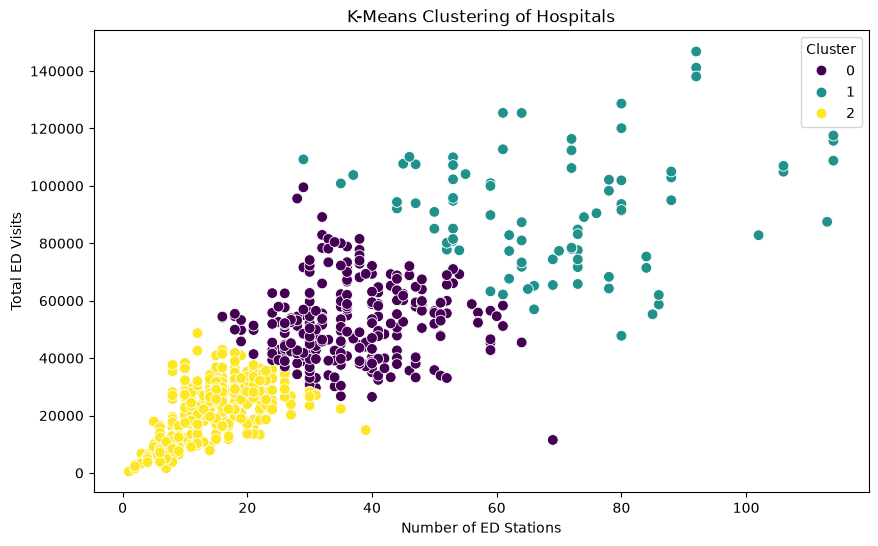

Silhouette score: 0.519

Cluster sizes and averages:
         Hospital_years  Mean_stations  Mean_visits
Cluster                                            
0                   273           37.0      51849.0
1                    88           70.0      90682.0
2                   395           14.0      19818.0

Share of each cluster in a mental health shortage area:
MentalHealthShortageArea     No    Yes
Cluster                               
0                         0.652  0.348
1                         0.705  0.295
2                         0.537  0.463


In [15]:
#Trying to use K-Means Clustering
from sklearn.metrics import silhouette_score

# Select the two features
X = data[["EDStations", "Tot_ED_NmbVsts"]].copy()

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create K-Means model
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Fit model
clusters = kmeans.fit_predict(X_scaled)

# Add cluster labels to original data
data["Cluster"] = clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=data,
    x="EDStations",
    y="Tot_ED_NmbVsts",
    hue="Cluster",
    palette="viridis",
    s=60
)

plt.title("K-Means Clustering of Hospitals")
plt.xlabel("Number of ED Stations")
plt.ylabel("Total ED Visits")
plt.show()

print("Silhouette score:", round(silhouette_score(X_scaled, clusters), 3))
print("\nCluster sizes and averages:")
print(data.groupby("Cluster").agg(Hospital_years=("EDStations", "size"), Mean_stations=("EDStations", "mean"),
                                  Mean_visits=("Tot_ED_NmbVsts", "mean")).round(0))
print("\nShare of each cluster in a mental health shortage area:")
print(pd.crosstab(data["Cluster"], data["MentalHealthShortageArea"], normalize="index").round(3))

K-means divides the hospitals into three size bands: 395 hospital-years with small EDs (about 14 stations and 19,800 visits on average), 273 mid-sized (about 37 stations and 51,800 visits), and 88 large (about 70 stations and 90,700 visits). The silhouette score of 0.519 is moderate. The plot explains what that number means here: the points form one continuous band from the lower left to the upper right, and K-means has simply cut that band into three pieces. The clusters are a sensible way to label hospitals as small, medium, or large, but they are not naturally separate groups.

The clusters also do not line up strongly with mental health shortage areas. The share in a shortage area is 46% for the small EDs, 35% for the mid-sized, and 30% for the large. Smaller EDs are somewhat more likely to be in a shortage area, which fits what Section 1.1 found about non-urban hospitals, but size alone does not sort hospitals by shortage status.

### 2.1.2 Clusters from longitude, latitude, and ED burden

Size alone gives one continuous cloud, so we try three features that describe where a hospital is and how hard its ED is working: `LONGITUDE`, `LATITUDE`, and `ED_Burden`. We ask for four clusters and draw them in 3D, colored by cluster.

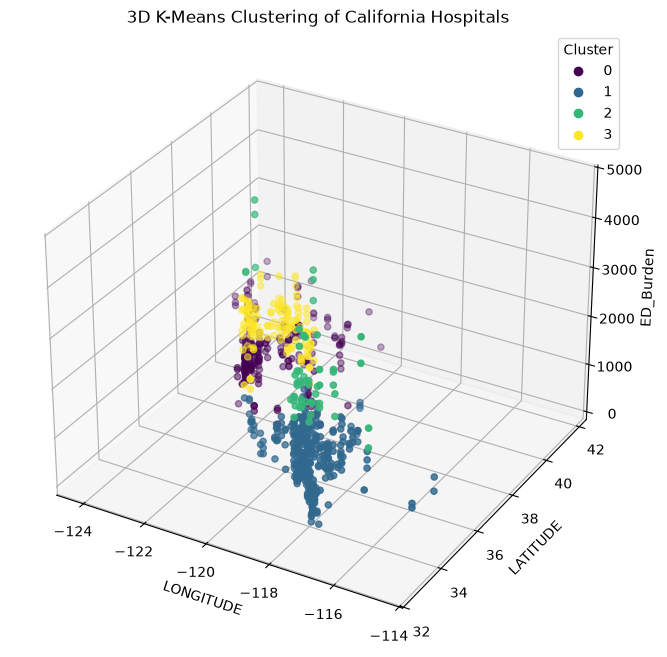

Silhouette score: 0.456

Cluster sizes and averages:
         Hospital_years  Mean_longitude  Mean_latitude  Mean_burden  \
Cluster                                                               
0                   215         -121.93          38.43      1154.99   
1                   350         -118.02          34.08      1276.49   
2                    57         -118.33          34.43      2814.71   
3                   134         -121.37          37.72      2001.29   

         Urban_share  
Cluster               
0               0.65  
1               0.87  
2               0.86  
3               0.73  


In [16]:
#We will try now with 3 features: Longitude, Latitude, and Burden

from mpl_toolkits.mplot3d import Axes3D

X = data[["LONGITUDE", "LATITUDE", "ED_Burden"]].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
data["Cluster"] = kmeans.fit_predict(X_scaled)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    X["LONGITUDE"],
    X["LATITUDE"],
    X["ED_Burden"],
    c=data["Cluster"],
    cmap="viridis"
)

ax.set_xlabel("LONGITUDE")
ax.set_ylabel("LATITUDE")
ax.set_zlabel("ED_Burden")
ax.set_title("3D K-Means Clustering of California Hospitals")
ax.legend(*scatter.legend_elements(), title="Cluster")

plt.show()

print("Silhouette score:", round(silhouette_score(X_scaled, data["Cluster"]), 3))
print("\nCluster sizes and averages:")
print(data.groupby("Cluster").agg(Hospital_years=("ED_Burden", "size"), Mean_longitude=("LONGITUDE", "mean"),
                                  Mean_latitude=("LATITUDE", "mean"), Mean_burden=("ED_Burden", "mean"),
                                  Urban_share=("UrbanRuralDesi", lambda s: (s == "Urban").mean())).round(2))

With location and burden, the four clusters have clearer identities. Two are regional groups with ordinary burden: a Southern California cluster (350 hospital-years, about 1,280 visits per station, 87% urban) and a Northern California cluster (215 hospital-years, about 1,150 visits per station, 65% urban). The other two are defined by heavy use. One is a group of 134 northern and central hospital-years with elevated burden (about 2,000 visits per station), and the other is a small group of 57 mostly southern hospital-years with very high burden (about 2,800 visits per station, roughly double the typical level).

The silhouette score is 0.456, a little lower than in 2.1.1, and the 3D plot shows that the clusters touch each other, with some hospitals that do not fit neatly into any of them. Even so, this grouping is more useful for our project. The two high-burden clusters pick out the hospitals where each treatment station is working hardest, which is the group our project goal is concerned with.

### 2.1.3 Choosing the number of clusters

We chose four clusters by eye. To check that choice, we run K-means for k = 2 through 10 on the same three features and record two measures for each k: the inertia (the total squared distance from each point to its cluster center, which always falls as k grows) and the silhouette score. In the elbow method, we look for the k where inertia stops falling quickly.

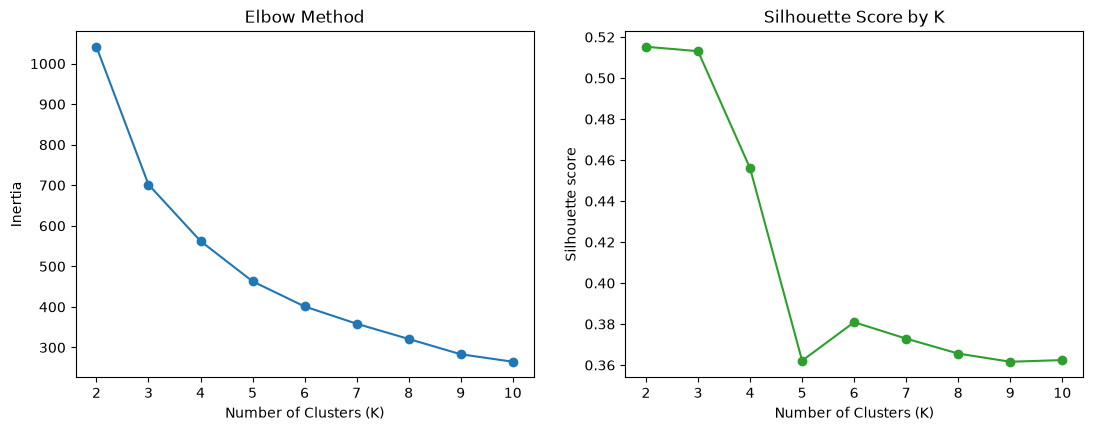

 K  Inertia  Silhouette
 2   1041.7       0.515
 3    701.8       0.513
 4    562.4       0.456
 5    463.1       0.362
 6    401.1       0.381
 7    358.5       0.373
 8    321.0       0.366
 9    283.3       0.362
10    264.7       0.362


In [17]:
#Elbow Method for the 3D Clustering
inertias = []
silhouettes = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(range(2, 11), inertias, marker="o")
axes[0].set(xlabel="Number of Clusters (K)", ylabel="Inertia", title="Elbow Method")

axes[1].plot(range(2, 11), silhouettes, marker="o", color="tab:green")
axes[1].set(xlabel="Number of Clusters (K)", ylabel="Silhouette score", title="Silhouette Score by K")

plt.show()

print(pd.DataFrame({"K": range(2, 11), "Inertia": np.round(inertias, 1),
                    "Silhouette": np.round(silhouettes, 3)}).to_string(index=False))

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

data["Cluster"] = kmeans.fit_predict(X_scaled)

The inertia curve bends gradually and has no sharp elbow. The largest drops come from k = 2 to 3 (1,041.7 to 701.8) and from 3 to 4 (701.8 to 562.4), and after that each added cluster helps less. The silhouette score is highest at k = 2 and k = 3 (0.515 and 0.513), falls to 0.456 at k = 4, and then drops sharply to 0.362 at k = 5.

The two measures therefore point to three or four clusters. Three gives slightly tighter clusters. We keep four because the fourth cluster separates the very-high-burden hospitals from the moderately high ones, a distinction that matters for our project, and the cost in silhouette score is modest. Five or more clusters are not supported by either measure.

## 2.2 Hierarchical Clustering

Hierarchical clustering builds a tree. It starts with every observation as its own cluster and repeatedly merges the two closest clusters until only one remains. The tree, called a dendrogram, shows which observations join early (very similar) and which join late (very different).

To look at the data from a new angle, we change the unit of observation from hospitals to health systems. Each of the 32 systems is described by five averages across its hospitals: mean total ED visits, mean ED stations, and the percentage of its hospital-years that are in a primary care shortage area, in a mental health shortage area, and urban. We standardize the five features and merge clusters with Ward's method, which joins the pair that increases within-cluster variance the least.

                                   Tot_ED_NmbVsts  EDStations  PrimaryCareShortageArea  MentalHealthShortageArea  Urban
system                                                                                                                 
AHMC Healthcare, Inc.                     18699.7        13.9                      7.7                       7.7  100.0
Adventist Health Systems                  35486.0        20.7                     67.4                      76.7   34.9
Alameda Health System                     39865.8        34.7                      0.0                       0.0  100.0
Alta Hospitals System                      6675.3         9.1                     20.0                      20.0  100.0
Avanti Hospitals                          20545.0        10.4                     45.5                      45.5  100.0
Cedars-Sinai Health System                51727.5        31.9                     37.5                       0.0  100.0
Cottage Health                          

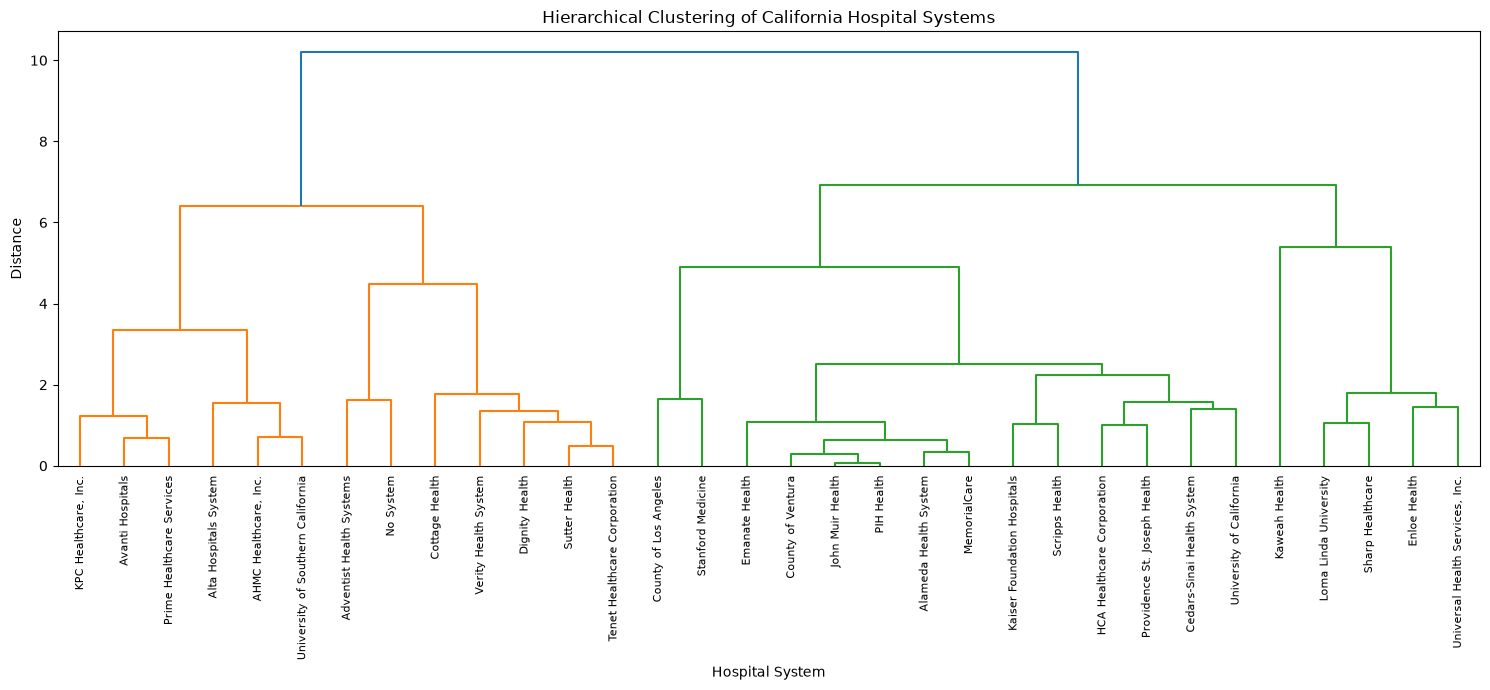

In [18]:
#Trying to use Hierarchical Clustering

#We investigate the hospital systems, with each system being one observation

systemData = data.groupby("system").agg(
    Tot_ED_NmbVsts=("Tot_ED_NmbVsts", "mean"),
    EDStations=("EDStations", "mean"),
    PrimaryCareShortageArea=(
        "PrimaryCareShortageArea",
        lambda x: (x == "Yes").mean() * 100
    ),
    MentalHealthShortageArea=(
        "MentalHealthShortageArea",
        lambda x: (x == "Yes").mean() * 100
    ),
    Urban=(
        "UrbanRuralDesi",
        lambda x: (x == "Urban").mean() * 100
    )
)

print(systemData.round(1).to_string())

scaler = StandardScaler()
X = scaler.fit_transform(systemData)

dist = pdist(X)

clusterModel = linkage(dist, method="ward")

plt.figure(figsize=(15, 7))

dendrogram(
    clusterModel,
    labels=systemData.index,
    leaf_rotation=90
)

plt.title("Hierarchical Clustering of California Hospital Systems")
plt.xlabel("Hospital System")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

The table shows how different the systems are. Average ED visits range from under 7,000 (Alta Hospitals System) to over 75,000 (Stanford Medicine), and the share of a system's hospitals in a mental health shortage area runs from 0% to 100%.

In the dendrogram, the height at which two systems join shows how different they are. Systems that join near the bottom are very similar; for example, John Muir Health, PIH Health, and County of Ventura merge almost immediately, as all three are fully urban, mid-sized, and outside any shortage area. The tree's first split, at a distance of about 10, separates the systems into two broad families: on the left, systems with smaller EDs or a mix of rural and shortage-area hospitals, and on the right, systems with larger, urban EDs.

To judge how well the tree represents the data, we compute the cophenetic correlation, which compares the distances implied by the tree with the original distances between systems (values close to 1 mean the tree is faithful). We then cut the tree into four groups and list the systems in each, with the group averages.

In [19]:
from scipy.cluster.hierarchy import cophenet, fcluster

coph_corr, _ = cophenet(clusterModel, dist)
print("Cophenetic correlation:", round(coph_corr, 3))

systemData["Group"] = fcluster(clusterModel, t=4, criterion="maxclust")
print("Silhouette score for four groups:", round(silhouette_score(X, systemData["Group"]), 3))

for group, members in systemData.groupby("Group"):
    print(f"\nGroup {group} ({len(members)} systems): " + "; ".join(members.index))

print("\nGroup averages:")
print(systemData.groupby("Group").mean().round(1).to_string())

Cophenetic correlation: 0.581
Silhouette score for four groups: 0.341

Group 1 (6 systems): AHMC Healthcare, Inc.; Alta Hospitals System; Avanti Hospitals; KPC Healthcare, Inc.; Prime Healthcare Services; University of Southern California

Group 2 (7 systems): Adventist Health Systems; Cottage Health; Dignity Health; No System; Sutter Health; Tenet Healthcare Corporation; Verity Health System

Group 3 (14 systems): Alameda Health System; Cedars-Sinai Health System; County of Los Angeles; County of Ventura; Emanate Health; HCA Healthcare Corporation; John Muir Health; Kaiser Foundation Hospitals; MemorialCare; PIH Health; Providence St. Joseph Health; Scripps Health; Stanford Medicine; University of California

Group 4 (5 systems): Enloe Health; Kaweah Health; Loma Linda University; Sharp Healthcare; Universal Health Services, Inc.

Group averages:
       Tot_ED_NmbVsts  EDStations  PrimaryCareShortageArea  MentalHealthShortageArea  Urban
Group                                           

Cutting the tree into four groups gives a readable summary of California's hospital systems:

1. Small urban systems (6 systems, including Prime Healthcare Services and AHMC Healthcare): entirely urban, with the smallest EDs, averaging about 19,000 visits and 14 stations.
2. Mixed and rural-serving systems (7 systems, including Adventist Health, Dignity Health, Sutter Health, and the independent "No System" hospitals): only about 66% urban, with mid-sized EDs and about half of their hospitals in mental health shortage areas.
3. Large urban systems outside shortage areas (14 systems, including Kaiser, Stanford Medicine, and the University of California): almost entirely urban, large EDs averaging about 52,600 visits, and very few hospitals in shortage areas (about 4% for mental health).
4. Large systems in shortage areas (5 systems, including Kaweah Health and Sharp Healthcare): the largest EDs on average, about 59,300 visits, with about 79% of their hospitals in mental health shortage areas.

As for effectiveness, the cophenetic correlation is 0.581 and the silhouette score for four groups is 0.341. Both are moderate. The tree captures the broad structure of the data but distorts some of the distances between individual systems, so the groups should be read as a helpful summary, not as sharp categories. The fourth group is the most relevant to our project: these systems combine the highest ED volume with widespread shortage areas, so their EDs are likely to be absorbing demand that other local services cannot meet. Systems in the same group face similar conditions, and a planner looking at one of them could reasonably look at the others in that group too.

## Conclusion

In this report we applied two supervised and two unsupervised learning methods to the hospital-level emergency department data.

For supervised learning, K-nearest Neighbors with two size features could not predict a hospital's health system (about 29% to 30% accuracy against a 27% no-skill rate) and did only slightly better than guessing on mental health shortage areas. Splitting the data showed why shortage status is hard to predict from size: it depends mostly on whether a hospital is urban, with about 84% of non-urban hospitals in a shortage area against 28% of urban ones. The Support Vector Machine, given six features and tuned by cross-validation, classified urban and rural hospitals with 91.4% accuracy and a balanced accuracy of 0.880 on hospitals it had never seen, ahead of logistic regression, KNN, and the no-skill rate of 79.0%. Adding location to an SVM also raised the accuracy on mental health shortage areas from no better than guessing to 79.0%.

For unsupervised learning, K-means on stations and visits sorted hospitals into small, medium, and large (silhouette 0.519), while K-means on location and burden produced four groups, two of which isolate the hospitals with the heaviest load per station (silhouette 0.456). Hierarchical clustering of the 32 health systems produced four interpretable groups, including a set of large systems that operate mostly in shortage areas.

We took several lessons from this work:

1. The features matter more than the algorithm. KNN and the SVM both failed with two size features, and both improved sharply when location was included.
2. Accuracy has to be compared with a no-skill rate. Two KNN models reported 72.5% and 85.3% accuracy, and both were exactly equal to guessing the majority class.
3. Class imbalance needs attention. Balanced class weights were the single most useful setting for the SVM, because they stopped the model from neglecting the smaller rural and frontier group.
4. Test data must be truly unseen. Because each hospital appears in several years, we held out whole hospitals, and the SVM's test score matched its cross-validated score closely.
5. Clustering results need a measure of quality and a plain-language reading. The silhouette scores told us our clusters are moderate, not sharp, and the cluster averages told us what each group means.

For our project goal of directing ED resources where demand is highest, this report adds two practical tools. The clusters identify the hospitals and health systems under the heaviest load, and the classifiers show that a hospital's location and size are enough to place it in the right setting with good reliability. Together with the regression model from Reports #2 and #3, these give planners a way to estimate expected demand, find hospitals that exceed it, and compare them with similar hospitals elsewhere in the state.